# SGI-6.11 — Who counts as a mutant?

**Marvel Superstars**, week 6 (exercise 6.11, "Go nuts with your LLM"). Same 303 characters, same Wikipedia pages.

**The question.** Every tool from week 6 can be asked the same thing: *which characters count as mutants?* The
word itself says one thing, a topic model another, and word vectors give *mutant* a different set of neighbours each.
How far apart are the answers, and what decides them?

The post keeps the question fixed and changes only the representation, in the order of the week-6 page: first
documents (a page described by its words), then words (a word described by its contexts). The ruler is always a
cosine or a topic weight; what changes is the vectors it is applied to.

**The answer key.** Wikipedia's own `Category:Marvel Comics mutants`, fetched once and saved to
`Data/Week6/mutant_category.tsv`. It is a label somebody else wrote, not ground truth, so the last section reads the
pages where the answers disagree.

Every number in the post comes from this notebook through `stats.json`. Each section ends with a **Result**
written after reading the output.

In [1]:
import datetime, json, math, re, sys, time, urllib.parse, urllib.request, zipfile
from collections import Counter
from pathlib import Path

import gensim, gensim.downloader as api, matplotlib, matplotlib.pyplot as plt, networkx as nx, numpy as np, pandas as pd
import scipy, scipy.sparse as sp, sklearn
from gensim.models import Word2Vec
from gensim.utils import simple_preprocess
from IPython.display import display
from nltk.corpus import stopwords
from scipy.optimize import linear_sum_assignment
from scipy.stats import pearsonr, spearmanr
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer

for m in (np, pd, nx, scipy, sklearn, gensim, matplotlib):
    print(f"{m.__name__:12s} {m.__version__}")
print("python      ", sys.version.split()[0])

DATA1, DATA5, DATA6 = Path("../../Data/Week1"), Path("../../Data/Week5"), Path("../../Data/Week6")
FIG = Path("../../Figures/Week6"); FIG.mkdir(parents=True, exist_ok=True); DATA6.mkdir(parents=True, exist_ok=True)
POST = Path("../../posts/week6/index.html")
SEED = 611
STATS = {}
PAPER, INK, MID, RULE, ACC, ACC2 = "#FBFAF7", "#17161C", "#6E6A73", "#E6E2DA", "#6B3FD4", "#D9480F"
plt.rcParams.update({"figure.facecolor": PAPER, "axes.facecolor": PAPER, "savefig.facecolor": PAPER, "font.size": 10.5,
                     "axes.edgecolor": MID, "axes.labelcolor": INK, "xtick.color": MID, "ytick.color": MID,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

numpy        2.2.6
pandas       3.0.6
networkx     3.7
scipy        1.13.1
sklearn      1.9.1
gensim       4.4.0
matplotlib   3.11.2
python       3.12.15


## 1. Load the network, the pages and the answer key

The network is week 1's (303 characters, 1,784 links); the pages come from the course zip. We keep the zip's own
page order for Word2Vec, because the week-6 page's *hammer* example depends on it (section 4 checks that we get the
page's list back). The tokenizer is the one behind the course explorables (lowercase, runs of letters with an optional
inner apostrophe), so our counts can be checked against the course's.

In [2]:
nodes = pd.read_csv(DATA1 / "week1_nodes.tsv", sep="\t", comment="#", quoting=3).set_index("node_id")
edges = pd.read_csv(DATA1 / "week1_edges.tsv", sep="\t", comment="#", names=["source", "target"])
G = nx.DiGraph(); G.add_nodes_from(nodes.index); G.add_edges_from(edges.itertuples(index=False))
U = G.to_undirected()
with zipfile.ZipFile(DATA5 / "marvel_pages.zip") as z:
    pages = {urllib.parse.unquote(n.split("/")[-1][:-4]): z.read(n).decode("utf-8")
             for n in z.namelist() if n.endswith(".txt") and "README" not in n}
ZIP_ORDER = list(pages)                                           # dicts keep insertion order: the zip's order
KEYS = sorted(pages); N = len(KEYS)
assert set(KEYS) == set(nodes.index) and G.number_of_edges() == 1784
name = nodes["name"].replace({"Phoenix (Guardians of the Galaxy)": "Phoenix Force"})   # week 1's Wikidata label is wrong for this page
BY_NAME = {name[k]: k for k in KEYS}

WORD = re.compile(r"[^\W\d_]+(?:['’][^\W\d_]+)?")
toks = {k: WORD.findall(pages[k].lower()) for k in KEYS}
length = pd.Series({k: len(toks[k]) for k in KEYS})
assert length.sum() == 727261                                     # the week-5 page's token count
print(f"{N} pages, {length.sum():,} tokens")

303 pages, 727,261 tokens


**The answer key.** We ask Wikipedia which of our 303 titles sit directly in `Category:Marvel Comics mutants`
(fetched once; the file is reused afterwards). Two choices. We do **not** follow its four subcategories (*Big Hero 6*,
*Madame Web*, *Scarlet Witch*, *X-Men*): they collect articles *about* a team or a character, not mutants. And we do
**not** follow redirects: a title that now redirects (12 of ours, mostly Strikeforce: Morituri members merged into a
list) has no categories of its own, so it would be counted "not a mutant" for the wrong reason. Those 12 are
*unknown* and left out of every comparison with the key.

In [3]:
CAT_FILE, CATEGORY = DATA6 / "mutant_category.tsv", "Category:Marvel Comics mutants"
UA = {"User-Agent": "SGI-course-exercise/1.0 (DTU 02805 student project)"}


def wiki(params):
    url = "https://en.wikipedia.org/w/api.php?" + urllib.parse.urlencode({**params, "format": "json"})
    return json.load(urllib.request.urlopen(urllib.request.Request(url, headers=UA)))


if not CAT_FILE.exists():
    status = {}
    for i in range(0, N, 50):
        batch = [k.replace("_", " ") for k in KEYS[i:i + 50]]; cont = {}
        while True:
            r = wiki({"action": "query", "titles": "|".join(batch), "prop": "info|categories", "cllimit": "max",
                      "clcategories": CATEGORY, **cont})
            for p in r["query"]["pages"].values():
                s = "redirect" if ("redirect" in p or "missing" in p) else ("member" if p.get("categories") else "not")
                status[p["title"]] = s if status.get(p["title"]) != "member" else "member"
            if "continue" not in r: break
            cont = r["continue"]
    rows = [(k, status[k.replace("_", " ")]) for k in KEYS]
    with open(CAT_FILE, "w", encoding="utf-8") as f:
        f.write(f"# {CATEGORY}, direct members only, redirects not followed; fetched {datetime.date.today()}\n")
        pd.DataFrame(rows, columns=["node_id", "status"]).to_csv(f, sep="\t", index=False)
print(CAT_FILE.read_text(encoding="utf-8").splitlines()[0])
cat = pd.read_csv(CAT_FILE, sep="\t", comment="#").set_index("node_id")["status"].reindex(KEYS)
LAB = cat != "redirect"                                           # pages with a label
TRUTH = cat == "member"
print(cat.value_counts().to_string())
print("unknown (redirects):", ", ".join(name[k] for k in KEYS if not LAB[k]))
STATS["key"] = dict(category=CATEGORY, fetched=CAT_FILE.read_text(encoding="utf-8").split("fetched ")[1][:10],
                    members=int(TRUTH.sum()), labelled=int(LAB.sum()), unknown=int((~LAB).sum()))


def score(pred):
    """how a yes/no answer over the pages compares with the key, on labelled pages only"""
    p, t = pred[LAB], TRUTH[LAB]
    tp = int((p & t).sum())
    return dict(said=int(p.sum()), hits=tp, precision=round(tp / max(int(p.sum()), 1), 3), recall=round(tp / int(t.sum()), 3))

# Category:Marvel Comics mutants, direct members only, redirects not followed; fetched 2026-10-11
status
not         242
member       49
redirect     12
unknown (redirects): Backhand (character), Blackthorn (character), Dargo Ktor, Radian (Morituri), Scaredycat, Scatterbrain (Morituri), Shear (character), Silencer (comics), Snapdragon (Morituri), Toxyn, Vindicator (comics), Vyking


**Result.** 49 of the 291 pages with a label are in the category; 12 titles now redirect and stay *unknown*.
That is the yardstick: a perfect answer would name those 49 and nobody else.

## 2. The word

The bluntest answer: a character is a mutant if the page says so. We count *mutant*, *mutants* and their possessives.
Then we weight the word the week-6 way, with TF-IDF as the page defines it, tf(t, d) = count(t, d) / |d| and
idf(t) = ln(N / df(t)), to see whose page it actually *describes*: a word on a third of the pages is common, but not
common enough to be silenced the way *marvel* and *comics* are (idf 0).

In [4]:
MUT = {"mutant", "mutants", "mutant's", "mutants'", "mutant’s", "mutants’"}
uses = pd.Series({k: sum(t in MUT for t in toks[k]) for k in KEYS})
says = uses > 0
df_mut = int(sum("mutant" in set(toks[k]) for k in KEYS))
idf_mut = math.log(N / df_mut)
print(f"{int(says.sum())} of {N} pages say mutant(s), {int(uses.sum()):,} uses; 'mutant' alone: df = {df_mut}, "
      f"idf = ln({N}/{df_mut}) = {idf_mut:.3f}")
STATS["word"] = dict(pages=int(says.sum()), uses=int(uses.sum()), df=df_mut, idf=round(idf_mut, 3))

# the full TF-IDF matrix (page definitions, names kept), to read fingerprints
vocab = sorted({t for k in KEYS for t in toks[k]}); col = {t: j for j, t in enumerate(vocab)}
rows, cols, vals = [], [], []
for i, k in enumerate(KEYS):
    for t, c in Counter(toks[k]).items():
        rows.append(i); cols.append(col[t]); vals.append(c)
CNT = sp.csr_matrix((vals, (rows, cols)), shape=(N, len(vocab)), dtype=float)
DF = np.asarray((CNT > 0).sum(axis=0)).ravel()
TFIDF = sp.diags(1 / length.values) @ CNT @ sp.diags(np.log(N / DF))
TFIDF = TFIDF.tocsr()
fp = {k: [vocab[j] for j in np.argsort(-TFIDF[i].toarray().ravel())[:10]] for i, k in enumerate(KEYS)}
in_fp = pd.Series({k: bool(MUT & set(fp[k])) for k in KEYS})
w = TFIDF[:, col["mutant"]].toarray().ravel()
top_mut = [(name[KEYS[i]], round(float(w[i]), 4), int(uses[KEYS[i]])) for i in np.argsort(-w)[:8]]
print(f"'mutant(s)' is among the 10 highest-weighted words on {int(in_fp.sum())} pages")
print("highest tf-idf for 'mutant':", top_mut)
STATS["word"].update(fingerprint_pages=int(in_fp.sum()), top=top_mut)

112 of 303 pages say mutant(s), 913 uses; 'mutant' alone: df = 97, idf = ln(303/97) = 1.139


'mutant(s)' is among the 10 highest-weighted words on 7 pages
highest tf-idf for 'mutant': [('Redneck (comics)', 0.0224, 7), ('Rusty Collins', 0.0117, 20), ('Powerhouse (Marvel Comics)', 0.0105, 5), ('Fabio Medina', 0.009, 10), ('Ogre (Marvel Comics)', 0.0068, 2), ('Empath (character)', 0.0063, 14), ('G. W. Bridge', 0.0061, 5), ('Rockslide (character)', 0.0057, 10)]


**Two groups, one word.** The week-6 page compares two communities word by word with Scattertext. We take the two
Louvain communities from SGI-6.3 (seed 0 on the undirected week-1 network): the X-Men (44 pages) and the cosmic
characters (39). Every word's rate per 10,000 words in each group is one dot; *mutant* should sit far from the diagonal.

In [5]:
comms = sorted(nx.community.louvain_communities(U, seed=0), key=len, reverse=True)
XMEN = next(c for c in comms if "Wolverine_(character)" in c)
COSMIC = next(c for c in comms if "Adam_Warlock" in c)
print("community sizes:", [len(c) for c in comms][:9], "| X-Men", len(XMEN), "| cosmic", len(COSMIC))
assert (len(XMEN), len(COSMIC)) == (44, 39)                       # SGI-6.3's two communities
STOP = set(stopwords.words("english"))


def rates(group):
    c = Counter(t for k in group for t in toks[k])
    return c, sum(c.values())


cx, nx_ = rates(XMEN); cc, nc_ = rates(COSMIC)
terms = [t for t in set(cx) | set(cc) if cx[t] + cc[t] >= 14 and t not in STOP and len(t) > 2]
scatter = sorted([[t, round(cx[t] / nx_ * 1e4, 2), round(cc[t] / nc_ * 1e4, 2)] for t in terms], key=lambda r: r[0])
mx, mc = cx["mutant"] / nx_ * 1e4, cc["mutant"] / nc_ * 1e4
px, pc = sum(says[k] for k in XMEN), sum(says[k] for k in COSMIC)
print(f"{len(terms):,} terms; mutant: {mx:.1f} vs {mc:.1f} per 10,000 words; pages saying it {px}/{len(XMEN)} vs {pc}/{len(COSMIC)}")
far = sorted(terms, key=lambda t: -abs(math.log((cx[t] / nx_ * 1e4 + .12) / (cc[t] / nc_ * 1e4 + .12))))[:12]
print("furthest from the diagonal:", far)
STATS["groups"] = dict(xmen=len(XMEN), cosmic=len(COSMIC), terms=len(terms), mutant_rate=[round(mx, 1), round(mc, 1)],
                       mutant_pages=[int(px), int(pc)], xmen_members=int(sum(TRUTH[k] for k in XMEN)))

community sizes: [44, 40, 39, 36, 35, 33, 32, 18, 9] | X-Men 44 | cosmic 39
1,783 terms; mutant: 23.2 vs 1.3 per 10,000 words; pages saying it 39/44 vs 10/39
furthest from the diagonal: ['cyclops', 'betsy', 'vell', 'varr', 'ares', 'jean', 'moondragon', 'eternals', 'summers', 'phyla', 'jubilee', 'genis']


In [6]:
ans = {"says it once": says, "says it 5+ times": uses >= 5, "top-10 TF-IDF word": in_fp,
       "X-Men community": pd.Series({k: k in XMEN for k in KEYS})}
word_table = pd.DataFrame({a: score(p) for a, p in ans.items()}).T
print(f"key: {int(TRUTH.sum())} members among {int(LAB.sum())} labelled pages")
display(word_table)
miss = [name[k] for k in KEYS if TRUTH[k] and not says[k]]
loud = sorted([(name[k], int(uses[k])) for k in KEYS if LAB[k] and not TRUTH[k] and uses[k] >= 5], key=lambda x: -x[1])
print("members who never say it:", miss)
print("say it 5+ times, not members:", loud)
STATS["word"].update(table=word_table.reset_index().values.tolist(), silent_members=miss, loud_nonmembers=loud)

key: 49 members among 291 labelled pages


,said,hits,precision,recall
says it once,111.0,47.0,0.423,0.959
says it 5+ times,40.0,31.0,0.775,0.633
top-10 TF-IDF word,7.0,6.0,0.857,0.122
X-Men community,43.0,30.0,0.698,0.612


members who never say it: ['Agent X (Marvel Comics)', 'Shamrock (comics)']
say it 5+ times, not members: [('Phoenix Force', 16), ('Cloak and Dagger (characters)', 14), ('Deadpool', 14), ('Bird-Brain (Marvel Comics)', 13), ('Gwenpool', 6), ('Mayday Parker', 6), ('Frog-Man', 5), ('G. W. Bridge', 5), ('Hrimhari', 5)]


**Result.** The word is a generous test. 112 pages say it (913 uses), which catches 47 of the 49 category
members (recall 0.96) but also 64 pages that are not in it (precision 0.42). The page text shows why: Deadpool's and
Bird-Brain's uses are mostly the title of a comic, *The New Mutants*; Phoenix Force is a cosmic entity whose page is
full of X-Men. Raising the bar to five uses trades recall for precision (0.78 / 0.63). TF-IDF barely helps here:
*mutant* has idf ln(303/97) = 1.139, a mid-weight word, and makes the top-10 fingerprint of only 7 pages, because
names outweigh it on almost every page. In the two-community comparison the word is as lopsided as expected (23.2 vs
1.3 uses per 10,000 words; on 39 of 44 X-Men pages vs 10 of 39 cosmic ones), but the X-Men community itself is only
30 of the 49 members. The two members who never say the word, Agent X and Shamrock, are the first hint that the
label knows things the text does not.

## 3. The theme

LDA describes a page differently: as a **mixture of topics**, where each topic is a probability distribution over
words. A page can lean on a "mutant" topic without using the word at all, as long as it uses the topic's other words.
That is the promise. The catch, which the week-6 page names but does not show: the number of topics K, the random
seed and the preprocessing all change the fit.

We use the page's own code and its name filter (words capitalized in most of their uses are removed, letters only,
min_df 5, max_df 0.5), and fit K ∈ {5, 8, 12} with seeds 0–19: 60 models.

**Three things the page leaves open, and how we close them with the page's own words.**
1. *Which topic is "the mutant topic"?* Topic numbers are arbitrary, so every fit needs a rule. The page says the
   label is ours, read off a topic's high-probability words: its example list is headed by *mutant* (*mutant,
   school, gene, telepath, sentinel*) and "we might decide to call it *mutants*". So the mutant topic is the one whose
   **top word is *mutant* or *mutants***; if two are, the one where that word is more probable. If none is, the fit
   **has no mutant topic**: the page expects topics to "split, merge or disappear" between fits, and tells us to say
   so when a topic is incoherent "instead of forcing a name onto it" (exercise 6.5).
   *A looser rule we tried first and dropped:* *mutant* anywhere in the 8 top words the page's code prints. At seed 19
   (every K) it labels a catch-all topic holding about 70% of the corpus (*list, voiced, father, mutant, written,
   playable…*) as "mutants". We keep that rule's counts below as a warning about labelling from top words alone.
2. *Who counts as a member?* Exercise 6.4 contrasts a page with mixture [0.70, 0.20, 0.10], easy to summarize with
   one label, and one with [0.35, 0.35, 0.30], which is not. We use **θ > 0.5**: the lowest cut that separates those
   two examples, and, because a page's θ sums to 1, the point where the mutant topic outweighs all other topics combined.
3. *How big is a topic?* We report its share of the corpus's tokens, Σ_d |d|·θ_dk / Σ_d |d| (a page of 3,000 words
   weighs more than one of 300), and print the plain average of θ next to it.

In [7]:
seen, capd = Counter(), Counter()                                # the page's name filter
for text in pages.values():
    for t in re.findall(r"[A-Za-z]+", text):
        seen[t.lower()] += 1; capd[t.lower()] += t[0].isupper()
proper = {t for t in seen if capd[t] > seen[t] / 2}
vec = CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | proper), min_df=5, max_df=0.5, token_pattern=r"(?u)\b[a-zA-Z]{2,}\b")
X = vec.fit_transform(pages[k] for k in KEYS); V = vec.get_feature_names_out()
L = np.asarray(X.sum(axis=1)).ravel(); MI = int(np.where(V == "mutant")[0][0])
print(f"{X.shape[0]} × {X.shape[1]:,} document-term matrix, {L.sum():,} counted tokens")


def cosines(phi_a, phi_b):
    a = phi_a / np.linalg.norm(phi_a, axis=1, keepdims=True); b = phi_b / np.linalg.norm(phi_b, axis=1, keepdims=True)
    return a @ b.T


def match(phi_ref, phi):
    """one-to-one partner in `phi` of every reference topic (Hungarian assignment on cosine)"""
    r, order = linear_sum_assignment(-cosines(phi_ref, phi))
    return order


TOP_N, CUT = 8, 0.5                                               # the page's printout length; 6.4's one-label cut
HEADS = [MI, int(np.where(V == "mutants")[0][0])]


def mutant_topic(theta, phi):
    """(k, members, qualifying): the topic whose top word is 'mutant' or 'mutants' (k = -1 if none; if several, the one
    where that word is most probable), the pages with θ > CUT in it, and how many topics were headed that way."""
    head = phi.argmax(axis=1)
    ok = [j for j in range(len(phi)) if head[j] in HEADS]
    if not ok:
        return -1, np.zeros(len(theta), bool), 0
    k = max(ok, key=lambda j: phi[j, head[j]])
    return k, theta[:, k] > CUT, len(ok)


def loose_topic(phi):
    """the dropped rule: 'mutant' anywhere in the TOP_N words (best rank wins), for comparison only"""
    rank = (phi > phi[:, [MI]]).sum(axis=1)
    ok = np.where(rank < TOP_N)[0]
    return int(min(ok, key=lambda j: (rank[j], -phi[j, MI]))) if len(ok) else -1


KS, SEEDS = [5, 8, 12], list(range(20))
fits, t0 = {}, time.time()
for K in KS:
    for s in SEEDS:
        lda = LatentDirichletAllocation(n_components=K, random_state=s)
        th = lda.fit_transform(X); ph = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
        k, members, qual = mutant_topic(th, ph)
        fits[K, s] = dict(theta=th, phi=ph, k=k, members=members, qualifying=qual,
                          col=th[:, k] if k >= 0 else np.zeros(N))          # the page's weight on the mutant topic
print(f"{len(fits)} fits in {time.time() - t0:.0f} s")

303 × 5,667 document-term matrix, 180,909 counted tokens


60 fits in 91 s


In [8]:
Q = KEYS.index("Quasar_(character)")
recs = []
for (K, s), f in fits.items():
    th, ph, k, col_, mem = f["theta"], f["phi"], f["k"], f["col"], pd.Series(f["members"], index=KEYS)
    kl = loose_topic(ph)
    head_words = " ".join(V[np.argsort(-ph[int(np.argmax(ph[:, MI]))])[:5]])        # where 'mutant' went, if absent
    recs.append(dict(K=K, seed=s, has=k >= 0, words=" ".join(V[np.argsort(-ph[k])[:TOP_N]]) if k >= 0 else f"(none; mutant sits in: {head_words})",
                     qualifying=f["qualifying"], share=(col_ * L).sum() / L.sum(), mean_theta=col_.mean(),
                     members=int(mem.sum()), silent=int((mem & ~says).sum()), quasar=round(float(col_[Q]), 2),
                     loose_members=int((th[:, kl] > CUT).sum()) if kl >= 0 else 0, **{
                         f"key_{a}": b for a, b in score(mem).items() if a in ("hits", "precision", "recall")}))
R = pd.DataFrame(recs)
absent = {K: int(((R.K == K) & ~R.has).sum()) for K in KS}
print("fits without a mutant topic:", absent, "| with 2+ topics headed by mutant(s):",
      {K: int(((R.K == K) & (R.qualifying > 1)).sum()) for K in KS})
print("where 'mutant' went in those fits:")
display(R[~R.has][["K", "seed", "words"]])
print(f"the dropped looser rule (mutant anywhere in the top {TOP_N}): members up to {R.loose_members.max()} "
      f"(K, seed = {R.loc[R.loose_members.idxmax(), ['K', 'seed']].tolist()})")
P = R[R.has]                                                      # ranges over the fits that have a mutant topic
summary = P.groupby("K").agg(fits=("seed", "size"), share_lo=("share", "min"), share_hi=("share", "max"), members_lo=("members", "min"),
                             members_hi=("members", "max"), silent_lo=("silent", "min"), silent_hi=("silent", "max"),
                             quasar_in=("quasar", lambda q: int((q > 0.5).sum())), prec_lo=("key_precision", "min"),
                             prec_hi=("key_precision", "max"), rec_lo=("key_recall", "min"), rec_hi=("key_recall", "max"))
display(summary.round(3))
display(R[R.seed < 3].drop(columns=["has", "loose_members"]).round(3))
gap = (P.share - P.mean_theta).abs()
print(f"token share vs mean θ, largest gap: {gap.max():.3f} (K, seed = {P.loc[gap.idxmax(), ['K', 'seed']].tolist()})")
GAP = round(float(gap.max()), 3)

fits without a mutant topic: {5: 7, 8: 5, 12: 3} | with 2+ topics headed by mutant(s): {5: 0, 8: 2, 12: 4}
where 'mutant' went in those fits:


,K,seed,words
3,5,3,(none; mutant sits in: symbiote mutants mutant...
5,5,5,(none; mutant sits in: armor energy hand mutan...
6,5,6,(none; mutant sits in: list mutants mutant ene...
11,5,11,(none; mutant sits in: list mutants written re...
12,5,12,(none; mutant sits in: symbiote mutant mutants...
13,5,13,(none; mutant sits in: symbiote voiced playabl...
14,5,14,(none; mutant sits in: energy speed mutant sui...
24,8,4,(none; mutant sits in: vampire mutants blood m...
25,8,5,(none; mutant sits in: speed list mutants muta...
31,8,11,(none; mutant sits in: list energy powerful mu...


the dropped looser rule (mutant anywhere in the top 8): members up to 223 (K, seed = [5, 19])


,fits,share_lo,share_hi,members_lo,members_hi,silent_lo,silent_hi,quasar_in,prec_lo,prec_hi,rec_lo,rec_hi
K,,,,,,,,,,,,
5,13,0.032,0.422,8,137,2,66,5,0.250,0.667,0.041,0.837
8,15,0.031,0.427,10,126,2,57,3,0.309,0.781,0.102,0.776
12,17,0.031,0.386,8,121,2,54,2,0.278,0.833,0.061,0.735


,K,seed,words,qualifying,share,mean_theta,members,silent,quasar,key_hits,key_precision,key_recall
0,5,0,mutant mutants energy list relationship member...,1,0.383,0.364,107,54,0.93,40,0.417,0.816
1,5,1,mutants mutant energy relationship vol father ...,1,0.299,0.294,79,38,0.43,33,0.471,0.673
2,5,2,mutant mutants energy list reality powerful me...,1,0.414,0.417,137,66,0.87,38,0.281,0.776
20,8,0,mutant mutants energy relationship list member...,1,0.355,0.319,96,47,0.84,38,0.442,0.776
21,8,1,mutants mutant relationship father vol return ...,1,0.246,0.186,45,16,0.00,26,0.578,0.531
22,8,2,mutant mutants energy list relationship realit...,1,0.427,0.388,126,57,0.85,38,0.309,0.776
40,12,0,mutants mutant relationship energy list past m...,1,0.247,0.210,59,26,0.53,31,0.608,0.633
41,12,1,mutant mutants father left psychic living retu...,1,0.105,0.099,19,11,0.00,5,0.278,0.102
42,12,2,(none; mutant sits in: speed brother list arms...,0,0.000,0.000,0,0,0.00,0,0.000,0.000


token share vs mean θ, largest gap: 0.141 (K, seed = [8, 15])


In [9]:
# the page's stability check (6.5): match every seed's topics one-to-one to seed 0's and ask whether the topic our
# rule picks is the partner of the topic it picked at seed 0, i.e. the "same" mutant topic, refitted
assert all(fits[K, 0]["k"] >= 0 for K in KS)
agree = {K: sum(fits[K, s]["k"] == int(match(fits[K, 0]["phi"], fits[K, s]["phi"])[fits[K, 0]["k"]])
                for s in SEEDS[1:] if fits[K, s]["k"] >= 0) for K in KS}
print("seeds 1–19 with a mutant topic:", {K: 19 - absent[K] for K in KS},
      "| of which it is the refit of seed 0's:", agree)
thresh = {t: int((fits[8, 0]["col"] > t).sum()) for t in (0.3, 0.5, 0.7)}
print("K = 8, seed 0, members at θ > 0.3 / 0.5 / 0.7:", thresh)
STATS["theme"] = dict(matrix=list(X.shape), tokens=int(L.sum()), fits=len(fits), agree=agree, thresholds=thresh,
                      top_n=TOP_N, cut=CUT, gap=GAP, absent=absent, split={K: int(((R.K == K) & (R.qualifying > 1)).sum()) for K in KS},
                      loose_max=int(R.loose_members.max()), summary=summary.round(3).reset_index().to_dict("records"),
                      members_range=[int(P.members.min()), int(P.members.max())],
                      share_range=[round(float(P.share.min()), 3), round(float(P.share.max()), 3)],
                      quasar_in=int((R.quasar > 0.5).sum()), quasar_says=int(uses["Quasar_(character)"]))

seeds 1–19 with a mutant topic: {5: 12, 8: 14, 12: 16} | of which it is the refit of seed 0's: {5: 10, 8: 11, 12: 12}
K = 8, seed 0, members at θ > 0.3 / 0.5 / 0.7: {0.3: 129, 0.5: 96, 0.7: 62}


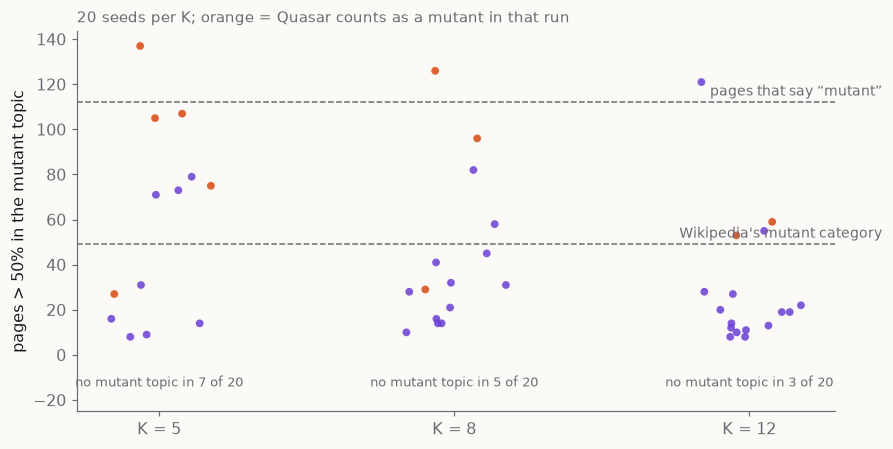

In [10]:
fig, ax = plt.subplots(figsize=(8.2, 4.2))
for i, K in enumerate(KS):
    r = P[P.K == K]
    jit = np.random.default_rng(SEED).uniform(-0.18, 0.18, len(r))
    ax.scatter(i + jit, r.members, s=26, color=[ACC2 if q > 0.5 else ACC for q in r.quasar], alpha=0.85, lw=0)
    ax.text(i, -14, f"no mutant topic in {absent[K]} of 20", ha="center", fontsize=8.5, color=MID)
for y, lab in [(int(says.sum()), "pages that say “mutant”"), (int(TRUTH.sum()), "Wikipedia's mutant category")]:
    ax.axhline(y, color=MID, lw=1, ls="--"); ax.text(2.45, y + 3, lab, color=MID, fontsize=9, ha="right")
ax.set_xticks(range(3), [f"K = {K}" for K in KS]); ax.set_ylim(-25, None); ax.set_ylabel("pages > 50% in the mutant topic")
ax.set_title("20 seeds per K; orange = Quasar counts as a mutant in that run", fontsize=10, color=MID, loc="left")
fig.tight_layout(); fig.savefig(FIG / "fig1_members.png", dpi=160); plt.show()

**Result.** The model does not always have a mutant topic. In 7 of 20 fits at K = 5 (5 at K = 8, 3 at K = 12) no
topic is headed by *mutant(s)*: the word has merged into a symbiote topic, a vampire topic, an armour-and-energy topic
or the media boilerplate. When the topic exists, it claims anywhere from **8 to 137 pages** and 3.1% to 42.7% of the
corpus's tokens, and its score against the key swings from precision 0.25 to 0.83 and recall 0.04 to 0.84. With the
page's own settings (K = 8, seed 0) it claims 96 pages, 35.5% of the tokens; at θ > 0.3 or 0.7 the same fit would
say 129 or 62. The 6.5 stability check agrees that this is mostly one topic refitted (10 of 12, 11 of 14 and 12 of
16 refits match seed 0's), so the instability is in its *size*, not its identity. Quasar, who never says the word,
counts as a mutant in 10 of the 60 fits: his page uses *energy* 15 times, and *energy* is the mutant topic's third
word. The looser top-8 rule would have called a catch-all topic "mutants" and claimed 223 pages.

## 4. The company

The topic model found Quasar through the company his words keep. The week-6 page turns that idea on words
themselves: a word is the row of contexts it appears in (a **word-context matrix**: one row per target word, one column
per context word, one cell = how often they occur within the window). Same ruler as before, cosine, but now applied to
four different kinds of row for *mutant*:

1. **raw counts** in a ±2 window (SGI-6.7's matrix: sentences, letters only, contexts with ≥ 10 uses, stopwords
   allowed as contexts but not as targets),
2. **PPMI** of the same matrix, PMI(w, c) = log2 P(w, c) / (P(w) P(c)), negatives clipped to 0,
3. **Word2Vec** trained on the pages with the week-6 page's settings (Skip-gram, window 5, 100 dimensions, seed 0),
4. **GloVe** (`glove-wiki-gigaword-100`), trained on Wikipedia and news, not on Marvel.

In [11]:
SENTS = [s for k in KEYS for s in (WORD.findall(x) for x in re.split(r"(?<=[.!?])\s+|\n+", pages[k].lower())) if s]
FREQ = Counter(t for s in SENTS for t in s)
CTX = sorted(t for t, n in FREQ.items() if n >= 10); TG = [t for t in CTX if t not in STOP]
COLC, ROW = {t: j for j, t in enumerate(CTX)}, {t: i for i, t in enumerate(TG)}
tr = np.array([ROW.get(t, -1) for s in SENTS for t in s]); tc = np.array([COLC.get(t, -1) for s in SENTS for t in s])
se = np.repeat(np.arange(len(SENTS)), [len(s) for s in SENTS])


def cooc(window):
    r, c = [], []
    for d in range(1, window + 1):
        same = se[:-d] == se[d:]
        for a, b in [(tr[:-d], tc[d:]), (tr[d:], tc[:-d])]:
            ok = same & (a >= 0) & (b >= 0); r.append(a[ok]); c.append(b[ok])
    r, c = np.concatenate(r), np.concatenate(c)
    return sp.csr_matrix((np.ones(len(r)), (r, c)), shape=(len(TG), len(CTX)))


def pmi_parts(C):
    C = C.tocoo(); T = C.sum(); rt = np.asarray(C.sum(axis=1)).ravel(); ct = np.asarray(C.sum(axis=0)).ravel()
    return C, T, rt, ct


def ppmi(C):
    C, T, rt, ct = pmi_parts(C)
    pmi = np.log2((C.data / T) / ((rt[C.row] / T) * (ct[C.col] / T)))
    keep = pmi > 0
    return sp.csr_matrix((pmi[keep], (C.row[keep], C.col[keep])), shape=C.shape)


def unit(M):
    n = np.sqrt(np.asarray(M.multiply(M).sum(axis=1)).ravel())
    return (sp.diags(1 / np.where(n == 0, 1, n)) @ M).tocsr()


C2 = cooc(2)
assert C2.sum() == 1286291 and C2[ROW["hammer"], COLC["thor's"]] == 8      # SGI-6.7's matrix and its checked cell
P2 = ppmi(C2)
print(f"±2 matrix: {C2.shape[0]:,} targets × {C2.shape[1]:,} contexts, {int(C2.sum()):,} pairs, {C2.nnz:,} nonzero cells")
STATS["company"] = dict(targets=C2.shape[0], contexts=C2.shape[1], pairs=int(C2.sum()), nonzero=int(C2.nnz),
                        doc_terms=len(vocab), mutant_uses=int(FREQ["mutant"]))

±2 matrix: 6,026 targets × 6,172 contexts, 1,286,291 pairs, 492,375 nonzero cells


**One cell by hand.** Before trusting the whole matrix: PMI for *mutant* with a context word that is everywhere
(*the*) and with a few that are not.

In [12]:
C2c, T2, rt2, ct2 = pmi_parts(C2)
cells = []
for c in ["the", "x", "powers", "mutants", "human", "gene"]:
    n = C2[ROW["mutant"], COLC[c]]
    pw, pc, pwc = rt2[ROW["mutant"]] / T2, ct2[COLC[c]] / T2, n / T2
    pmi = math.log2(pwc / (pw * pc)) if n else -math.inf
    cells.append(dict(context=c, count=int(n), row_total=int(rt2[ROW["mutant"]]), col_total=int(ct2[COLC[c]]),
                      P_wc=pwc, P_w=pw, P_c=pc, PMI=round(pmi, 3), PPMI=round(max(pmi, 0), 3)))
cells = pd.DataFrame(cells).set_index("context")
assert all(abs(P2[ROW["mutant"], COLC[c]] - cells.PPMI[c]) < 1e-3 for c in cells.index)   # hand == matrix
display(cells)
STATS["cells"] = dict(total=int(T2), rows=cells.reset_index().round(8).to_dict("records"))

,count,row_total,col_total,P_wc,P_w,P_c,PMI,PPMI
context,,,,,,,,
the,141,1659,103764,0.000110,0.00129,0.080669,0.075,0.075
x,28,1659,5080,0.000022,0.00129,0.003949,2.095,2.095
powers,30,1659,2005,0.000023,0.00129,0.001559,3.536,3.536
mutants,0,1659,697,0.000000,0.00129,0.000542,-inf,0.000
human,9,1659,1069,0.000007,0.00129,0.000831,2.707,2.707
gene,2,1659,99,0.000002,0.00129,0.000077,3.969,3.969


In [13]:
order = [k for k in ZIP_ORDER]                                    # the page's own iteration order (marvel_pages.values())
W2V_SENTS = [simple_preprocess(s) for k in order for s in re.split(r"(?<=[.!?])\s+", pages[k])]
W2V = dict(vector_size=100, window=5, min_count=5, sg=1, workers=1)
t0 = time.time()
w2v = {s: Word2Vec(W2V_SENTS, seed=s, **W2V) for s in range(5)}
print(f"5 Word2Vec models in {time.time() - t0:.0f} s (gensim prints harmless 'Exception ignored' lines while training)")
hammer = [t for t, _ in w2v[0].wv.most_similar("hammer", topn=6)]
print("seed 0, hammer:", hammer)
assert hammer == ["mjolnir", "odinson", "truck", "hide", "torn", "inevitably"]       # the week-6 page's list
glove = api.load("glove-wiki-gigaword-100")
assert glove.most_similar(positive=["king", "woman"], negative=["man"], topn=1)[0][0] == "queen"

Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'
Exception ignored in: 'gensim.models.word2vec_inner.our_dot_float'


5 Word2Vec models in 45 s (gensim prints harmless 'Exception ignored' lines while training)
seed 0, hammer: ['mjolnir', 'odinson', 'truck', 'hide', 'torn', 'inevitably']


**Compared to what?** A cosine of 0.8 means nothing on its own: each space has its own spread. So every space gets
the same baseline: 5,000 random pairs drawn from words that are about as common in the Marvel pages as *mutant*
(50 to 500 uses; *mutant* has 478) and exist in all four spaces. A neighbour's **percentile** is the share of random
pairs with a lower cosine. (Drawing from *all* words would be unfair to Word2Vec: rare words get few training updates
and stay bunched together, so the all-words baseline sits much higher; we print it too.)

In [14]:
wv0 = w2v[0].wv
POOL = sorted(t for t, n in FREQ.items() if 50 <= n <= 500 and t not in STOP and t in ROW and t in wv0.key_to_index
              and t in glove.key_to_index)
rng = np.random.default_rng(SEED)
A, B = rng.choice(len(POOL), 5000), rng.choice(len(POOL), 5000)
keep = A != B; A, B = A[keep], B[keep]
print(f"baseline pool: {len(POOL):,} words in all four spaces; {len(A):,} random pairs; 'mutant' has {FREQ['mutant']} uses")


class Sparse:
    def __init__(self, M): self.U = unit(M)
    def vec(self, t): return self.U[ROW[t]]
    def sims(self, t): return (self.U @ self.vec(t).T).toarray().ravel(), TG
    def pair(self, a, b): return np.asarray(self.U[[ROW[x] for x in a]].multiply(self.U[[ROW[x] for x in b]]).sum(axis=1)).ravel()


class Dense:
    def __init__(self, kv): self.kv, self.W = kv, kv.get_normed_vectors()
    def sims(self, t): return self.W @ self.W[self.kv.key_to_index[t]], self.kv.index_to_key
    def pair(self, a, b):
        i = [self.kv.key_to_index[x] for x in a]; j = [self.kv.key_to_index[x] for x in b]
        return (self.W[i] * self.W[j]).sum(axis=1)


SPACES = {"raw counts ±2": Sparse(C2), "PPMI ±2": Sparse(P2), "Word2Vec (Marvel)": Dense(wv0), "GloVe (Wikipedia + news)": Dense(glove)}
pa, pb = [POOL[i] for i in A], [POOL[i] for i in B]
rulers = {}
for lab, S in SPACES.items():
    base = np.sort(S.pair(pa, pb))
    sims, words = S.sims("mutant")
    order_ = [i for i in np.argsort(-sims) if words[i] != "mutant"][:8]
    nb = [(words[i], round(float(sims[i]), 3), round(float(np.searchsorted(base, sims[i]) / len(base)), 4)) for i in order_]
    rulers[lab] = dict(neighbours=nb, base_mean=round(float(base.mean()), 3), base_p99=round(float(np.percentile(base, 99)), 3),
                       hist=np.histogram(base, bins=40, range=(-0.2, 1.0))[0].tolist())
    print(f"{lab:26s} random mean {base.mean():.3f}, 99th {np.percentile(base, 99):.3f} | "
          + ", ".join(f"{t} {c:.2f} ({p:.0%})" for t, c, p in nb))
allw = rng.choice(len(wv0.index_to_key), (2, 5000))
print(f"Word2Vec baseline over ALL {len(wv0.index_to_key):,} words instead: mean "
      f"{(wv0.get_normed_vectors()[allw[0]] * wv0.get_normed_vectors()[allw[1]]).sum(1).mean():.3f}")
STATS["rulers"] = rulers
STATS["rulers_meta"] = dict(pool=len(POOL), pairs=int(len(A)), above_all={l: all(p == 1.0 for _, _, p in r["neighbours"]) for l, r in rulers.items()})

baseline pool: 1,540 words in all four spaces; 4,999 random pairs; 'mutant' has 475 uses
raw counts ±2              random mean 0.387, 99th 0.816 | supervillain 0.89 (100%), group 0.88 (100%), threat 0.88 (100%), pair 0.88 (100%), champion 0.88 (100%), gang 0.88 (100%), child 0.87 (100%), great 0.87 (100%)
PPMI ±2                    random mean 0.029, 99th 0.089 | mutants 0.16 (100%), powers 0.14 (100%), abilities 0.14 (100%), group 0.14 (100%), human 0.13 (100%), x 0.13 (100%), superhuman 0.12 (100%), utopia 0.12 (100%)
Word2Vec (Marvel)          random mean 0.401, 99th 0.751 | subspecies 0.78 (99%), omega 0.76 (99%), humans 0.75 (99%), magneto 0.72 (98%), supremacy 0.72 (98%), telepath 0.71 (98%), mutants 0.70 (98%), eternal 0.70 (98%)
GloVe (Wikipedia + news)   random mean 0.221, 99th 0.653 | mutants 0.73 (100%), mutated 0.62 (98%), ninja 0.61 (98%), superhero 0.60 (98%), werewolf 0.60 (98%), cyborg 0.59 (97%), mice 0.59 (97%), x-men 0.58 (97%)
Word2Vec baseline over ALL 9,526 words

In [15]:
core = Counter(t for s in range(5) for t, _ in w2v[s].wv.most_similar("mutant", topn=10))
print("Word2Vec, 'mutant' top 10 over 5 seeds, words in ≥ 4:", [t for t, n in core.most_common() if n >= 4])
nb10 = [t for t, _ in sorted(zip(*Sparse(ppmi(cooc(10))).sims("mutant")[::-1]), key=lambda x: -x[1]) if t != "mutant"][:8]
print("PPMI ±10:", nb10)
STATS["rulers_extra"] = dict(w2v_core=[t for t, n in core.most_common() if n >= 4], ppmi10=nb10)

Word2Vec, 'mutant' top 10 over 5 seeds, words in ≥ 4: ['subspecies', 'omega', 'humans', 'magneto', 'supremacy', 'telepath', 'mutants', 'hellions']


PPMI ±10: ['mutants', 'powers', 'x', 'magneto', 'abilities', 'later', 'men', 'jean']


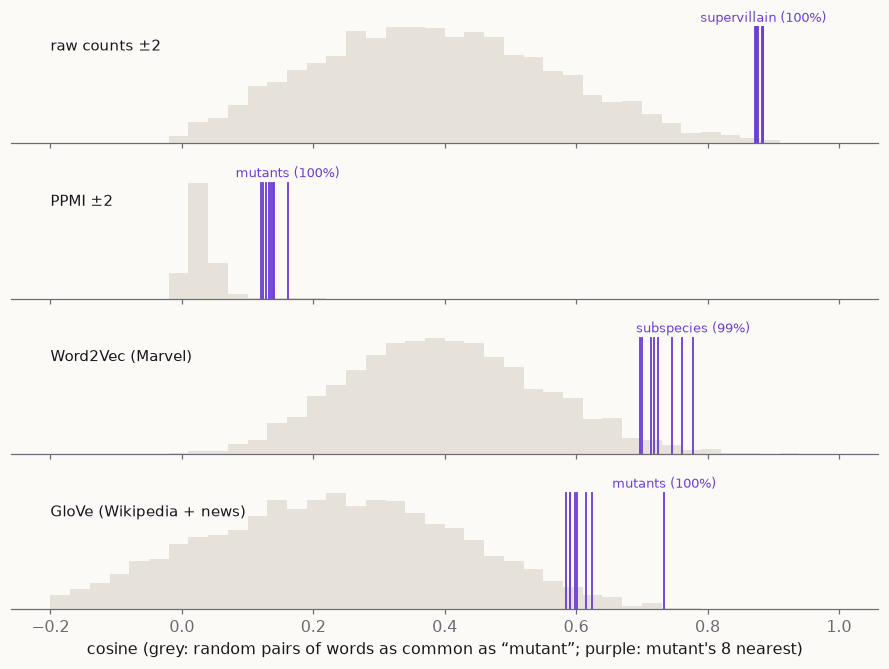

In [16]:
fig, axes = plt.subplots(len(SPACES), 1, figsize=(8.2, 6.2), sharex=True)
edges_ = np.linspace(-0.2, 1.0, 41)
for ax, (lab, r) in zip(axes, rulers.items()):
    ax.bar(edges_[:-1], r["hist"], width=edges_[1] - edges_[0], align="edge", color=RULE)
    top = max(r["hist"])
    for t, c, p in r["neighbours"]:
        ax.plot([c, c], [0, top], color=ACC, lw=1.2)
    t, c, p = r["neighbours"][0]
    ax.text(c, top * 1.02, f"{t} ({p:.0%})", color=ACC, fontsize=8.5, ha="center", va="bottom")
    ax.set_yticks([]); ax.spines["left"].set_visible(False)
    ax.text(-0.2, top * 0.8, lab, fontsize=9.5, color=INK)
axes[-1].set_xlabel("cosine (grey: random pairs of words as common as “mutant”; purple: mutant's 8 nearest)")
fig.tight_layout(); fig.savefig(FIG / "fig2_rulers.png", dpi=160); plt.show()

**Result.** The hand-computed cells agree with the matrix. *the* sits next to *mutant* 141 times, yet its PMI is
0.075, almost exactly what independence predicts; *powers* (30 times) scores 3.54. And *mutant* and *mutants* never
fall within two words of each other, so their PPMI is 0, although they are the same idea.

The four rulers then give four different kinds of "close". **Raw counts** find words used in the same slot
(*supervillain, group, threat, gang*: "a mutant ___" / "a ___ group"), at cosines of 0.87–0.89 that look huge until
you see that random pairs average 0.39. **PPMI** finds associates (*mutants, powers, abilities, human, superhuman,
utopia*) at cosines of only 0.12–0.16, against random pairs at 0.03. Measured as percentiles, the top neighbours of raw
counts (0.89) and of PPMI (0.16) both beat about 99.9% of random pairs: the two spaces agree that their neighbours are
close and disagree about which words they are. A cosine value only compares within one space. **Marvel Word2Vec** finds lore (*subspecies, omega, humans, magneto, supremacy, telepath*), stable
across five seeds, at 0.70–0.78 against a random 0.40 (0.67 if rare words are allowed into the baseline).
**GloVe** finds the outside world (*mutated, ninja, werewolf, cyborg, mice*): the same word, one vector, trained on
news where a mutant is a lab mouse. A wider window (±10) pulls PPMI toward topics (*magneto, jean, men*) and noise
(*later*). Same cosine every time; the vectors decide what it means.

## 5. Why two rulers agree

*Goodies, not on Test 2.* Word2Vec never builds the PPMI matrix, yet its neighbours often look like PPMI's. Levy and
Goldberg (2014), linked from the week-6 Goodies, explain why: Skip-gram with negative sampling learns a word vector
**w** and a context vector **c**, and at its optimum w · c = PMI(w, c) − log k, with k the number of negative
samples (gensim's default k = 5). gensim keeps the context vectors (`syn1neg`), so we can check this on Marvel: for
every word-context pair seen at least 10 times within ±5 words, plot w · c against PMI − ln 5.

Our counting is simpler than gensim's training (no random window shrinking, no down-sampling of frequent words,
negatives drawn from smoothed counts), so we expect a cloud around the line, not the line itself.

In [17]:
def lg_pairs(model, window=5, min_count=10):
    idx = model.wv.key_to_index
    ids = [np.array([idx[t] for t in s if t in idx]) for s in W2V_SENTS]
    seq = np.concatenate([i for i in ids if len(i)]); sid = np.repeat(np.arange(sum(len(i) > 0 for i in ids)), [len(i) for i in ids if len(i)])
    a, b = [], []
    for d in range(1, window + 1):
        same = sid[:-d] == sid[d:]
        a += [seq[:-d][same], seq[d:][same]]; b += [seq[d:][same], seq[:-d][same]]
    a, b = np.concatenate(a), np.concatenate(b)
    nV = len(idx); key, n = np.unique(a.astype(np.int64) * nV + b, return_counts=True)
    wa, wb = key // nV, key % nV
    tot = n.sum(); rowc = np.bincount(wa, weights=n, minlength=nV); colc = np.bincount(wb, weights=n, minlength=nV)
    keep = n >= min_count
    wa, wb, n = wa[keep], wb[keep], n[keep]
    pmi = np.log(n * tot / (rowc[wa] * colc[wb]))
    dot = (model.wv.vectors[wa] * model.syn1neg[wb]).sum(axis=1)
    return wa, wb, pmi, dot


LG = {}
for s in (0, 1):
    wa, wb, pmi, dot = lg_pairs(w2v[s])
    k = w2v[s].negative
    LG[s] = dict(pairs=len(pmi), pearson=round(float(pearsonr(pmi, dot)[0]), 3), spearman=round(float(spearmanr(pmi, dot)[0]), 3),
                 mean_dot=round(float(dot.mean()), 3), mean_shifted=round(float((pmi - math.log(k)).mean()), 3))
    print(f"seed {s}: {LG[s]}")
wa, wb, pmi, dot = lg_pairs(w2v[0]); kk = math.log(w2v[0].negative)
xr = (math.floor(np.percentile(pmi - kk, 0.5)), math.ceil(np.percentile(pmi - kk, 99.5)))
yr = (math.floor(np.percentile(dot, 0.5)), math.ceil(np.percentile(dot, 99.5)))
H, _, _ = np.histogram2d(pmi - kk, dot, bins=48, range=[xr, yr])
mi = w2v[0].wv.key_to_index["mutant"]; sel = wa == mi
mut_pts = sorted([[w2v[0].wv.index_to_key[c], round(float(x), 3), round(float(y), 3)] for c, x, y in zip(wb[sel], pmi[sel] - kk, dot[sel])],
                 key=lambda r: -r[1])
print(f"mutant's {sel.sum()} pairs: Pearson {pearsonr(pmi[sel], dot[sel])[0]:.2f}; highest PMI:", [r[0] for r in mut_pts[:8]])
STATS["lg"] = dict(k=w2v[0].negative, seeds=LG, mutant_pairs=int(sel.sum()), mutant_pearson=round(float(pearsonr(pmi[sel], dot[sel])[0]), 3))

seed 0: {'pairs': 71357, 'pearson': 0.727, 'spearman': 0.774, 'mean_dot': -1.083, 'mean_shifted': -0.896}


seed 1: {'pairs': 71357, 'pearson': 0.728, 'spearman': 0.776, 'mean_dot': -1.086, 'mean_shifted': -0.896}


mutant's 55 pairs: Pearson 0.78; highest PMI: ['population', 'nation', 'anti', 'krakoa', 'magneto', 'level', 'abilities', 'ability']


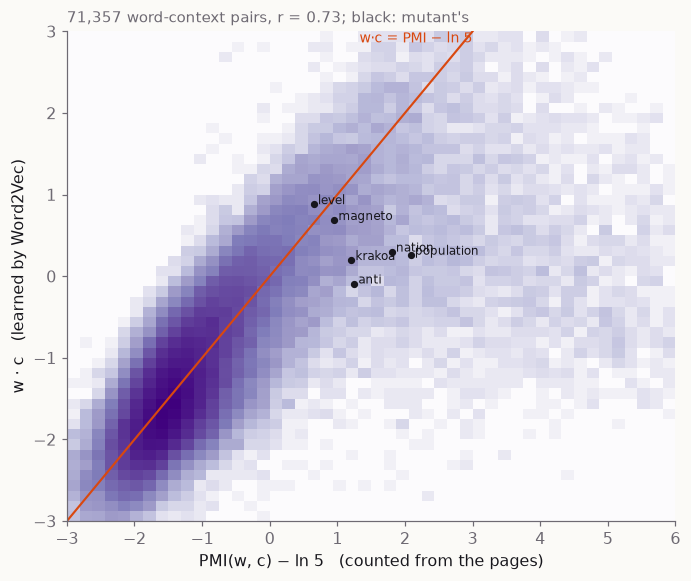

In [18]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.imshow(np.log1p(H.T), origin="lower", extent=[*xr, *yr], aspect="auto", cmap="Purples")
lo, hi = max(xr[0], yr[0]), min(xr[1], yr[1])
ax.plot([lo, hi], [lo, hi], color=ACC2, lw=1.4); ax.text(hi, hi, " w·c = PMI − ln 5", color=ACC2, fontsize=9, va="top", ha="right")
for t, x, y in mut_pts[:6]:
    ax.scatter(x, y, s=14, color=INK); ax.text(x, y, f" {t}", fontsize=8, color=INK)
ax.set(xlabel="PMI(w, c) − ln 5   (counted from the pages)", ylabel="w · c   (learned by Word2Vec)")
ax.set_title(f"{LG[0]['pairs']:,} word-context pairs, r = {LG[0]['pearson']:.2f}; black: mutant's", fontsize=10, color=MID, loc="left")
fig.tight_layout(); fig.savefig(FIG / "fig3_levy_goldberg.png", dpi=160); plt.show()

**Result.** On 71,357 word-context pairs, w · c and PMI − ln 5 correlate at r = 0.727 (seed 1: 0.728), and the
average w · c (−1.08) sits close to the average PMI − ln 5 (−0.90). For *mutant*'s own 55 pairs r = 0.78. Word2Vec
never saw the PMI matrix, yet it has learned a compressed, noisy copy of it, which is why its neighbours and PPMI's
so often agree. The copy is faithful only up to PMI − ln 5 ≈ 1: above that the cloud flattens below the line, so the
strongest (and mostly rarer) associations are the ones 100 dimensions cannot fully hold.

## 6. Verdict: read the pages where the answers disagree

Each answer from sections 2 and 3, scored against the key (labelled pages only). For LDA we show seed 0 at the
page's K = 8 and the range over all 60 fits.

In [19]:
k80 = pd.Series(fits[8, 0]["members"], index=KEYS)
member_frac = pd.Series(np.mean([f["members"] for f in fits.values()], axis=0), index=KEYS)
verdict = pd.DataFrame({**{a: score(p) for a, p in ans.items()}, "LDA, K = 8, seed 0": score(k80)}).T
lo_hi = {m: (P[f"key_{m}"].min(), P[f"key_{m}"].max()) for m in ("precision", "recall")}
display(verdict)
print(f"LDA over the {len(P)} fits with a mutant topic: said {P.members.min()}–{P.members.max()}, precision {lo_hi['precision'][0]:.2f}–{lo_hi['precision'][1]:.2f}, "
      f"recall {lo_hi['recall'][0]:.2f}–{lo_hi['recall'][1]:.2f}")
STATS["verdict"] = dict(table=verdict.reset_index().values.tolist(),
                        lda_range={m: [round(float(a), 3), round(float(b), 3)] for m, (a, b) in lo_hi.items()})

,said,hits,precision,recall
says it once,111.0,47.0,0.423,0.959
says it 5+ times,40.0,31.0,0.775,0.633
top-10 TF-IDF word,7.0,6.0,0.857,0.122
X-Men community,43.0,30.0,0.698,0.612
"LDA, K = 8, seed 0",86.0,38.0,0.442,0.776


LDA over the 45 fits with a mutant topic: said 8–137, precision 0.25–0.83, recall 0.04–0.84


In [20]:
topic_not_key = member_frac[LAB & ~TRUTH].sort_values(ascending=False).head(5)
key_not_topic = member_frac[TRUTH].sort_values().head(5)
print("most often in the topic, not in the key:", [(name[k], round(v, 2)) for k, v in topic_not_key.items()])
print("in the key, least often in the topic:  ", [(name[k], round(v, 2)) for k, v in key_not_topic.items()])
DISPUTED = list(dict.fromkeys(["Quasar_(character)", "Deadpool", "Phoenix_Force", "Agent_X_(Marvel_Comics)", "Shamrock_(comics)", "Starhawk_(character)",
                               "Sean_and_Chris", "Living_Lightning", "Synapse_(character)"]
                              + list(topic_not_key.index[:2]) + list(key_not_topic.index[:2])))


def kwic(k, terms, n=3, width=60):
    low = pages[k].replace("\n", " ")
    hits = [m.start() for m in re.finditer(r"\b(?:" + "|".join(terms) + r")\b", low, flags=re.I)]
    return [low[max(0, h - width):h + width].strip() for h in hits[:n]]


topic_words = set(V[np.argsort(-fits[8, 0]["phi"][fits[8, 0]["k"]])[:15]])
for k in DISPUTED:
    present = Counter(t for t in toks[k] if t in topic_words)
    print(f"\n■ {name[k]} | key: {cat[k]} | says mutant {uses[k]}× | in the topic in {member_frac[k]:.0%} of fits | "
          f"θ(K=8, seed 0) {fits[8, 0]['col'][KEYS.index(k)]:.2f}")
    print("  topic words on the page:", dict(present.most_common(6)))
    for line in kwic(k, ["mutants?"]) or kwic(k, ["energy"]):
        print("   …" + line + "…")

most often in the topic, not in the key: [('Bird-Brain (Marvel Comics)', 0.33), ('Starhawk (character)', 0.27), ('Phoenix Force', 0.27), ('Sean and Chris', 0.27), ('Living Lightning', 0.23)]
in the key, least often in the topic:   [('Whizzer (Robert Frank)', 0.02), ('Devil Dinosaur', 0.02), ('Gremlin (comics)', 0.07), ('Ricochet (comics)', 0.07), ('Silhouette (comics)', 0.07)]

■ Quasar (character) | key: not | says mutant 0× | in the topic in 17% of fits | θ(K=8, seed 0) 0.84
  topic words on the page: {'energy': 15, 'powerful': 1, 'speed': 1}
   …n technology that grants the wearer manipulation of quantum energy.   Fictional character biography   Wendell Vaughn Wen…
   …roves successful at wielding them, but he perishes when the energy output reaches a critical mass beyond his control. Va…
   …t on the facility. Using the bands' power to generate solid energy constructs, he repulses the attack. When the energy b…

■ Deadpool | key: not | says mutant 14× | in the topic in 5% of fits |

**What we read.** First pass by Claude Code, written after reading every line printed above; a group member re-reads
the pages and signs below before the post goes up.

In [21]:
READ = dict(
    word="Deadpool (14 uses) and Bird-Brain (13) are not mutants on their pages: nearly every use is the comic title "
         "The New Mutants, where they first appeared. Phoenix Force (16) is a cosmic entity; its page says mutant because "
         "it retells X-Men stories. Starhawk's 'mutants' are the last of an alien race on Arcturus, a second sense of the word.",
    topic="Quasar's and Living Lightning's powers come from energy (the Quantum Bands; a lightning weapon), and 'energy' is "
          "one of the mutant topic's top words, so the topic pulls them in. Sean and Chris (542 words) reach θ 0.99 at K = 8 "
          "seed 0 with almost no topic words: short pages get extreme mixtures. Synapse's page describes two telepaths and "
          "never says what they are; neither the text nor the key settles her.",
    key="Agent X (healing factor) and Shamrock (powers from the souls of war victims) are category members whose pages "
        "never call them mutants; Whizzer's page says it once ('retconned the character to be a mutant'), Devil Dinosaur's "
        "only about other characters. The category encodes knowledge the article text does not contain, so no text model "
        "can recover it from these pages.",
    first_pass="Claude Code, 2026-10-11", signed_off_by="",            # a group member fills this in after re-reading
)
for k, v in READ.items(): print(f"{k}: {v}")
STATS["read"] = READ

word: Deadpool (14 uses) and Bird-Brain (13) are not mutants on their pages: nearly every use is the comic title The New Mutants, where they first appeared. Phoenix Force (16) is a cosmic entity; its page says mutant because it retells X-Men stories. Starhawk's 'mutants' are the last of an alien race on Arcturus, a second sense of the word.
topic: Quasar's and Living Lightning's powers come from energy (the Quantum Bands; a lightning weapon), and 'energy' is one of the mutant topic's top words, so the topic pulls them in. Sean and Chris (542 words) reach θ 0.99 at K = 8 seed 0 with almost no topic words: short pages get extreme mixtures. Synapse's page describes two telepaths and never says what they are; neither the text nor the key settles her.
key: Agent X (healing factor) and Shamrock (powers from the souls of war victims) are category members whose pages never call them mutants; Whizzer's page says it once ('retconned the character to be a mutant'), Devil Dinosaur's only about oth

## 7. Data for the post's interactive figures

The post draws its charts in the browser from data embedded in the page (no fetch). The final check compares the
embedded copy with `STATS["viz"]`.

In [22]:
dial = {}
for (K, s), f in fits.items():
    ph, k, col_ = f["phi"], f["k"], f["col"]
    top = np.argsort(-ph[k])[:10] if k >= 0 else []
    dial[f"{K}|{s}"] = dict(words=[[V[j], round(float(ph[k, j]), 4)] for j in top], share=round(float((col_ * L).sum() / L.sum()), 4),
                           theta=[round(float(x), 2) for x in col_], k=k, qualifying=f["qualifying"],
                           members=[int(i) for i in np.where(f["members"])[0]],
                           merged=[] if k >= 0 else [V[j] for j in np.argsort(-ph[int(np.argmax(ph[:, MI]))])[:6]])
STATS["viz"] = dict(
    pages=[[name[k], int(uses[k]), cat[k], int(k in XMEN), int(length[k])] for k in KEYS], quasar=Q, dial=dial,
    scatter=scatter, rulers=rulers, lg=dict(H=H.astype(int).tolist(), x=list(xr), y=list(yr), mutant=mut_pts[:12]))
assert all(len(v["members"]) == int(fits[int(k.split("|")[0]), int(k.split("|")[1])]["members"].sum()) for k, v in dial.items())
size = len(json.dumps(STATS["viz"], ensure_ascii=False, separators=(",", ":")))
print(f"embedded data: {size / 1e6:.2f} MB")

embedded data: 0.15 MB


## 8. Every number, pinned

`stats.json` is the single source for the post. The checks pin the headline numbers, so a change in the data, the
code or a library fails loudly instead of leaving stale prose on the site.

In [23]:
Path("stats.json").write_text(json.dumps(STATS, ensure_ascii=False, indent=1), encoding="utf-8")
EXPECT = {("key", "members"): 49, ("key", "labelled"): 291, ("word", "pages"): 112, ("word", "uses"): 913,
          ("word", "df"): 97, ("word", "fingerprint_pages"): 7, ("groups", "mutant_pages"): [39, 10],
          ("theme", "absent"): {5: 7, 8: 5, 12: 3}, ("theme", "members_range"): [8, 137], ("theme", "quasar_in"): 10,
          ("theme", "loose_max"): 223, ("theme", "thresholds"): {0.3: 129, 0.5: 96, 0.7: 62},
          ("rulers_extra", "ppmi10"): ["mutants", "powers", "x", "magneto", "abilities", "later", "men", "jean"]}
for path, want in EXPECT.items():
    got = STATS
    for p in path: got = got[p]
    assert got == want, f"{'.'.join(path)}: expected {want}, got {got}"
assert STATS["lg"]["seeds"][0]["pearson"] == 0.727 and STATS["lg"]["seeds"][1]["pearson"] == 0.728
assert [w for w, _, _ in STATS["rulers"]["Word2Vec (Marvel)"]["neighbours"][:3]] == ["subspecies", "omega", "humans"]
assert [w for w, _, _ in STATS["rulers"]["PPMI ±2"]["neighbours"][:3]] == ["mutants", "powers", "abilities"]
if POST.exists():
    m = re.search(r'<script type="application/json" id="viz-data">(.*?)</script>', POST.read_text(encoding="utf-8"), re.S)
    assert m and json.loads(m.group(1)) == json.loads(json.dumps(STATS["viz"], ensure_ascii=False)), "post's embedded data is stale"
    print("post's embedded data matches STATS['viz']")
print(f"wrote stats.json ({len(STATS)} entries); all pinned numbers hold")

post's embedded data matches STATS['viz']


wrote stats.json (13 entries); all pinned numbers hold


## What we found

- **The word over-counts.** 112 pages say *mutant*; the category has 49. The word catches nearly every member
  (recall 0.96) but also every page that mentions *The New Mutants* or retells an X-Men story.
- **The topic model gives a different answer every time you ask.** Its mutant topic is missing in 3–7 of 20 fits per K
  (merged into symbiotes, vampires, armour or boilerplate) and, when present, claims 8 to 137 pages. Quasar is a mutant
  in 10 of 60 fits because his powers are made of *energy*.
- **"Close to *mutant*" depends on the vectors.** Raw counts give slot-fellows, PPMI associates, Marvel Word2Vec lore,
  GloVe lab mice. The cosine is the same ruler throughout; a value only means something next to its own baseline.
- **Counting and predicting meet.** Word2Vec's w · c tracks PMI − ln 5 at r ≈ 0.73, which is why PPMI and Word2Vec so
  often agree.
- **Some answers are not in the text.** Agent X and Shamrock are mutants by Wikipedia's category, but their pages never
  say so; no text representation can find them.

**Choices:** the course explorable's tokenizer; the page's LDA settings and name filter; the mutant topic = the topic
headed by *mutant(s)*, members θ > 0.5 (both derived from the week-6 page, section 3); random baselines from words as
common as *mutant*; `Category:Marvel Comics mutants`, direct members, no redirects. **Limitation:** the key is a
label someone wrote, and it disagrees with the pages in both directions; we report agreement with it, not accuracy.